# Détecteur et Classifieur d'Objets Spatiaux & Débris
Detecteur de Déchets 

Ce notebook prépare le pipeline complet de données avec **Pandas** et **TensorFlow**.
Chaque image contient un **unique objet** (satellite ou débris). Le pipeline génère ainsi deux cibles pour chaque image :
- `class_output` : l'identifiant de la classe (parmi 11 classes)
- `bbox_output` : les 4 coordonnées normalisées `[ymin, xmin, ymax, xmax]`

In [1]:
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import tensorflow as tf
import yaml

# Configuration globale
IMG_SIZE = 224  # Taille standard adaptée aux backbones CNN (ex: MobileNetV2, ResNet)
BATCH_SIZE = 16

DATA_YAML_PATH = 'data/data.yaml'
with open(DATA_YAML_PATH, 'r', encoding='utf-8') as yaml_file:
  dataset_config = yaml.safe_load(yaml_file)

CLASS_NAMES = dataset_config['names']
CLASS_NAMES
NUM_CLASSES = len(CLASS_NAMES)
print(f"TensorFlow version: {tf.__version__}")
print(f"Nombre de classes: {NUM_CLASSES}")


I0000 00:00:1791972277.744860   12603 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791972277.775679   12603 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791972278.723936   12603 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow version: 2.22.0-rc0
Nombre de classes: 11


## 1. Préparation des DataFrames Pandas

Nous lisons les annotations YOLO (`[class_id, x_center, y_center, width, height]`) et les convertissons directement en `[ymin, xmin, ymax, xmax]`.
Chaque image contenant un unique objet, nous n'avons plus besoin de padding `MAX_BOXES`.


In [2]:
def create_dataset_dataframe(image_dir):
    """
    Lit les images et leurs étiquettes YOLO pour créer un DataFrame Pandas tabulaire.
    """
    image_paths = sorted(glob.glob(os.path.join(image_dir, '*.jpg')))
    records = []

    for img_path in image_paths:
        label_path = img_path.replace('images', 'labels').replace('.jpg', '.txt')
        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                line = f.readline().strip()
                if line:
                    parts = line.split()
                    cls_id = int(parts[0])
                    x_c, y_c, w, h = map(float, parts[1:5])

                    # Conversion YOLO (x_center, y_center, w, h) -> (ymin, xmin, ymax, xmax)
                    ymin = max(0.0, y_c - (h / 2.0))
                    xmin = max(0.0, x_c - (w / 2.0))
                    ymax = min(1.0, y_c + (h / 2.0))
                    xmax = min(1.0, x_c + (w / 2.0))

                    records.append({
                        'image_path': img_path,
                        'class_id': cls_id,
                        'class_name': CLASS_NAMES[cls_id] if 0 <= cls_id < len(CLASS_NAMES) else 'unknown',
                        'ymin': ymin,
                        'xmin': xmin,
                        'ymax': ymax,
                        'xmax': xmax,
                    })

    return pd.DataFrame(records)

# Création des DataFrames
df_train = create_dataset_dataframe('data/train/images')
df_val   = create_dataset_dataframe('data/valid/images')
df_test  = create_dataset_dataframe('data/test/images')

print(f"Train : {len(df_train)} images")
print(f"Val   : {len(df_val)} images")
print(f"Test  : {len(df_test)} images")
df_train.head()


Train : 2105 images
Val   : 239 images
Test  : 123 images


,image_path,class_id,class_name,ymin,xmin,ymax,xmax
0,data/train/images/img000008_jpg.rf.2c95cb6fb03...,5,proba_2,0.369141,0.129297,0.865234,0.430078
1,data/train/images/img000008_jpg.rf.9f76dc15cc1...,5,proba_2,0.134766,0.129297,0.630859,0.430078
2,data/train/images/img000009_jpg.rf.1142d9cc183...,5,proba_2,0.341016,0.192578,0.969922,0.585547
3,data/train/images/img000009_jpg.rf.1c26d8ebd8e...,5,proba_2,0.341016,0.414453,0.969922,0.807422
4,data/train/images/img000009_jpg.rf.da7b45fe680...,5,proba_2,0.030078,0.192578,0.658984,0.585547


## 2. Exploration des données (EDA)
Vérifions la distribution des classes dans l'ensemble d'entraînement.


In [3]:
print("Distribution des classes (Train) :")
print(df_train['class_name'].value_counts())


Distribution des classes (Train) :
class_name
cheops                     214
proba_2                    213
xmm_newton                 198
double_start               196
proba_3_csc                191
lisa_pathfinder            190
smart_1                    188
debris                     186
soho                       183
earth_observation_sat_1    178
proba_3_ocs                168
Name: count, dtype: int64


## 3. Pipeline TensorFlow (`tf.data`)

Nous transformons directement les DataFrames Pandas en `tf.data.Dataset` optimisés via `tf.data.Dataset.from_tensor_slices` :
- Chargement et décodage multithreadés (`AUTOTUNE`)
- Redimensionnement à `IMG_SIZE` et normalisation dans `[0, 1]`
- Sortie au format dictionnaire `{'class_output': ..., 'bbox_output': ...}` prêt pour un modèle multi-tâches (classification + localisation)


In [4]:
def df_to_tf_dataset(df, img_size=IMG_SIZE, batch_size=BATCH_SIZE, is_training=True):
    image_paths = df['image_path'].values
    bboxes = df[['ymin', 'xmin', 'ymax', 'xmax']].values.astype(np.float32)
    class_ids = df['class_id'].values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices((image_paths, bboxes, class_ids))

    def load_and_preprocess(img_path, bbox, cls_id):
        img_raw = tf.io.read_file(img_path)
        img = tf.image.decode_jpeg(img_raw, channels=3)
        img = tf.image.resize(img, [img_size, img_size])
        img = tf.cast(img, tf.float32) / 255.0
        return img, {
            'class_output': cls_id,
            'bbox_output': bbox,
        }

    if is_training:
        dataset = dataset.shuffle(buffer_size=min(len(df), 1000), reshuffle_each_iteration=True)

    dataset = dataset.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

train_ds = df_to_tf_dataset(df_train, is_training=True)
val_ds   = df_to_tf_dataset(df_val, is_training=False)
test_ds  = df_to_tf_dataset(df_test, is_training=False)

print("Datasets TensorFlow construits et prêts pour l'entraînement !")


Datasets TensorFlow construits et prêts pour l'entraînement !


E0000 00:00:1791972279.690385   12603 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



## 4. Visualisation d'un lot pour vérification
Affichons un lot d'entraînement avec l'étiquette de classe et la boîte englobante correspondante.


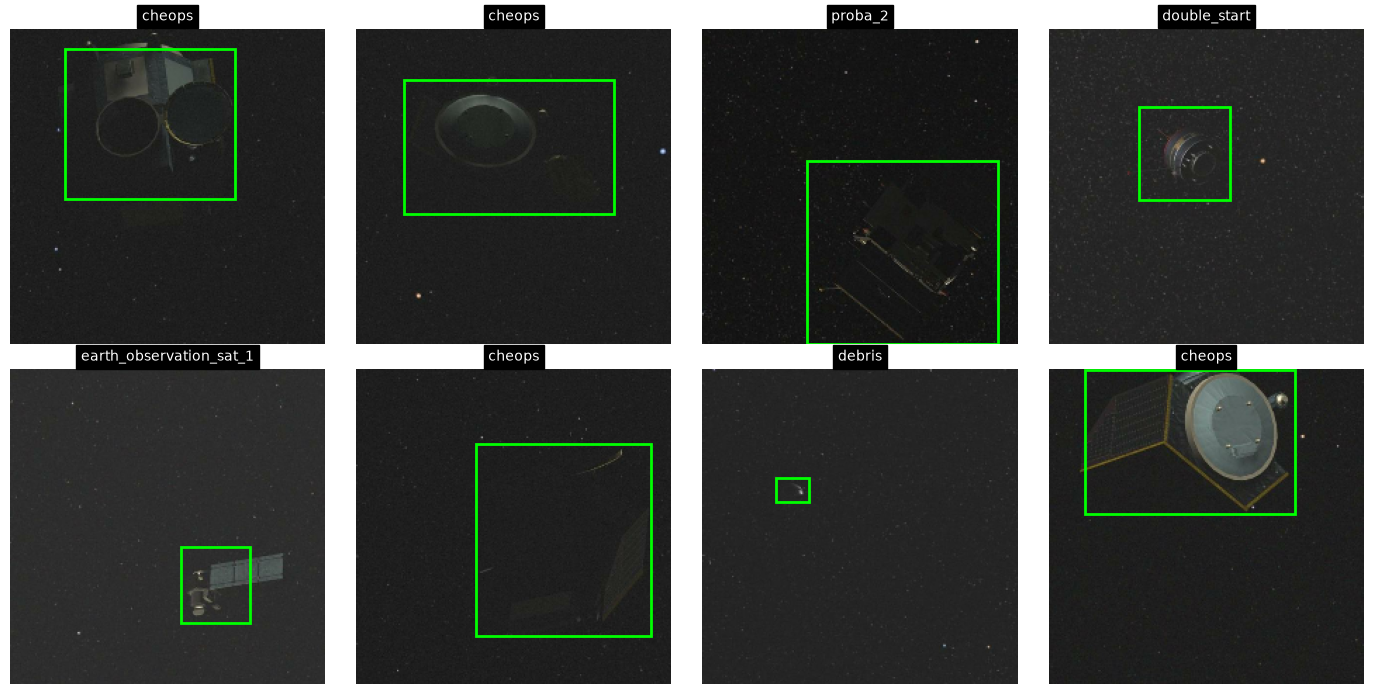

In [5]:
for images, targets in train_ds.take(1):
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    axes = axes.flatten()

    for i in range(min(8, len(images))):
        img = images[i].numpy()
        cls_id = int(targets['class_output'][i].numpy())
        ymin, xmin, ymax, xmax = targets['bbox_output'][i].numpy()

        h, w, _ = img.shape
        box_y = ymin * h
        box_x = xmin * w
        box_h = (ymax - ymin) * h
        box_w = (xmax - xmin) * w

        axes[i].imshow(img)
        rect = patches.Rectangle((box_x, box_y), box_w, box_h, linewidth=2, edgecolor='lime', facecolor='none')
        axes[i].add_patch(rect)
        axes[i].set_title(f"{CLASS_NAMES[cls_id]}", color='white', backgroundcolor='black', fontsize=10)
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()
    break


# Conversion des images en HSV 

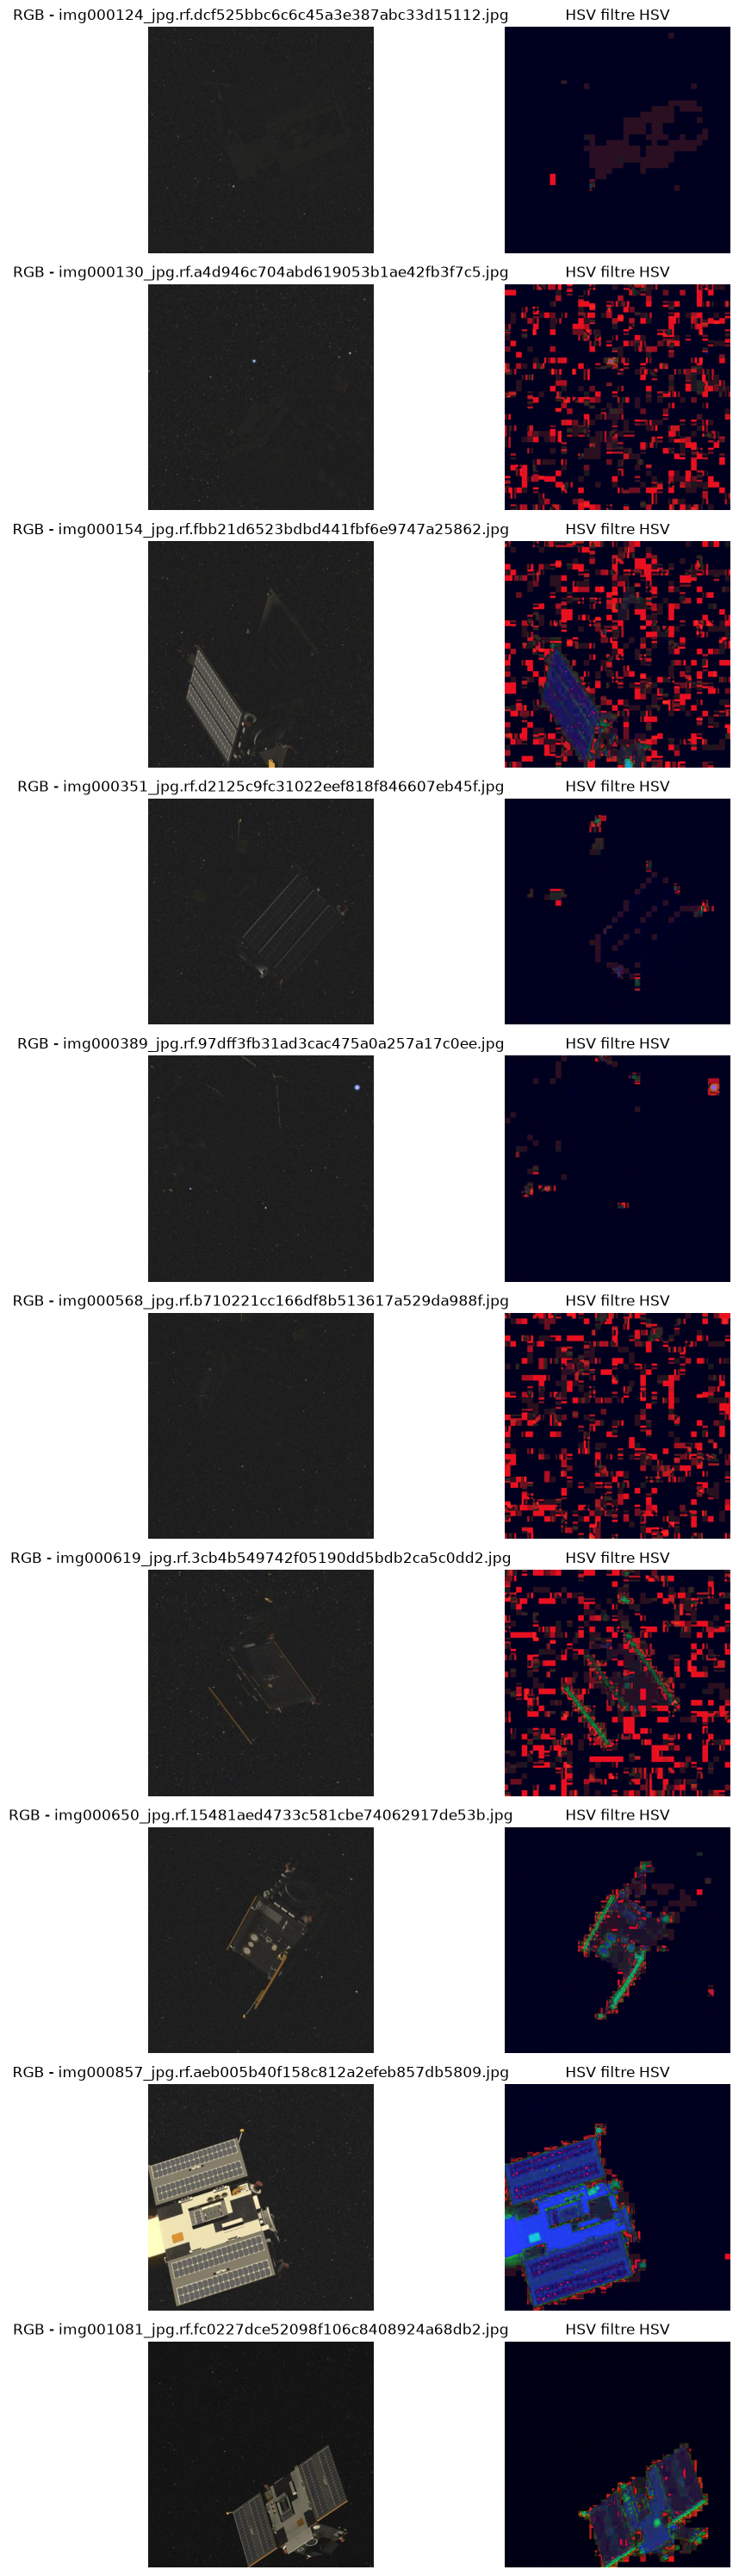

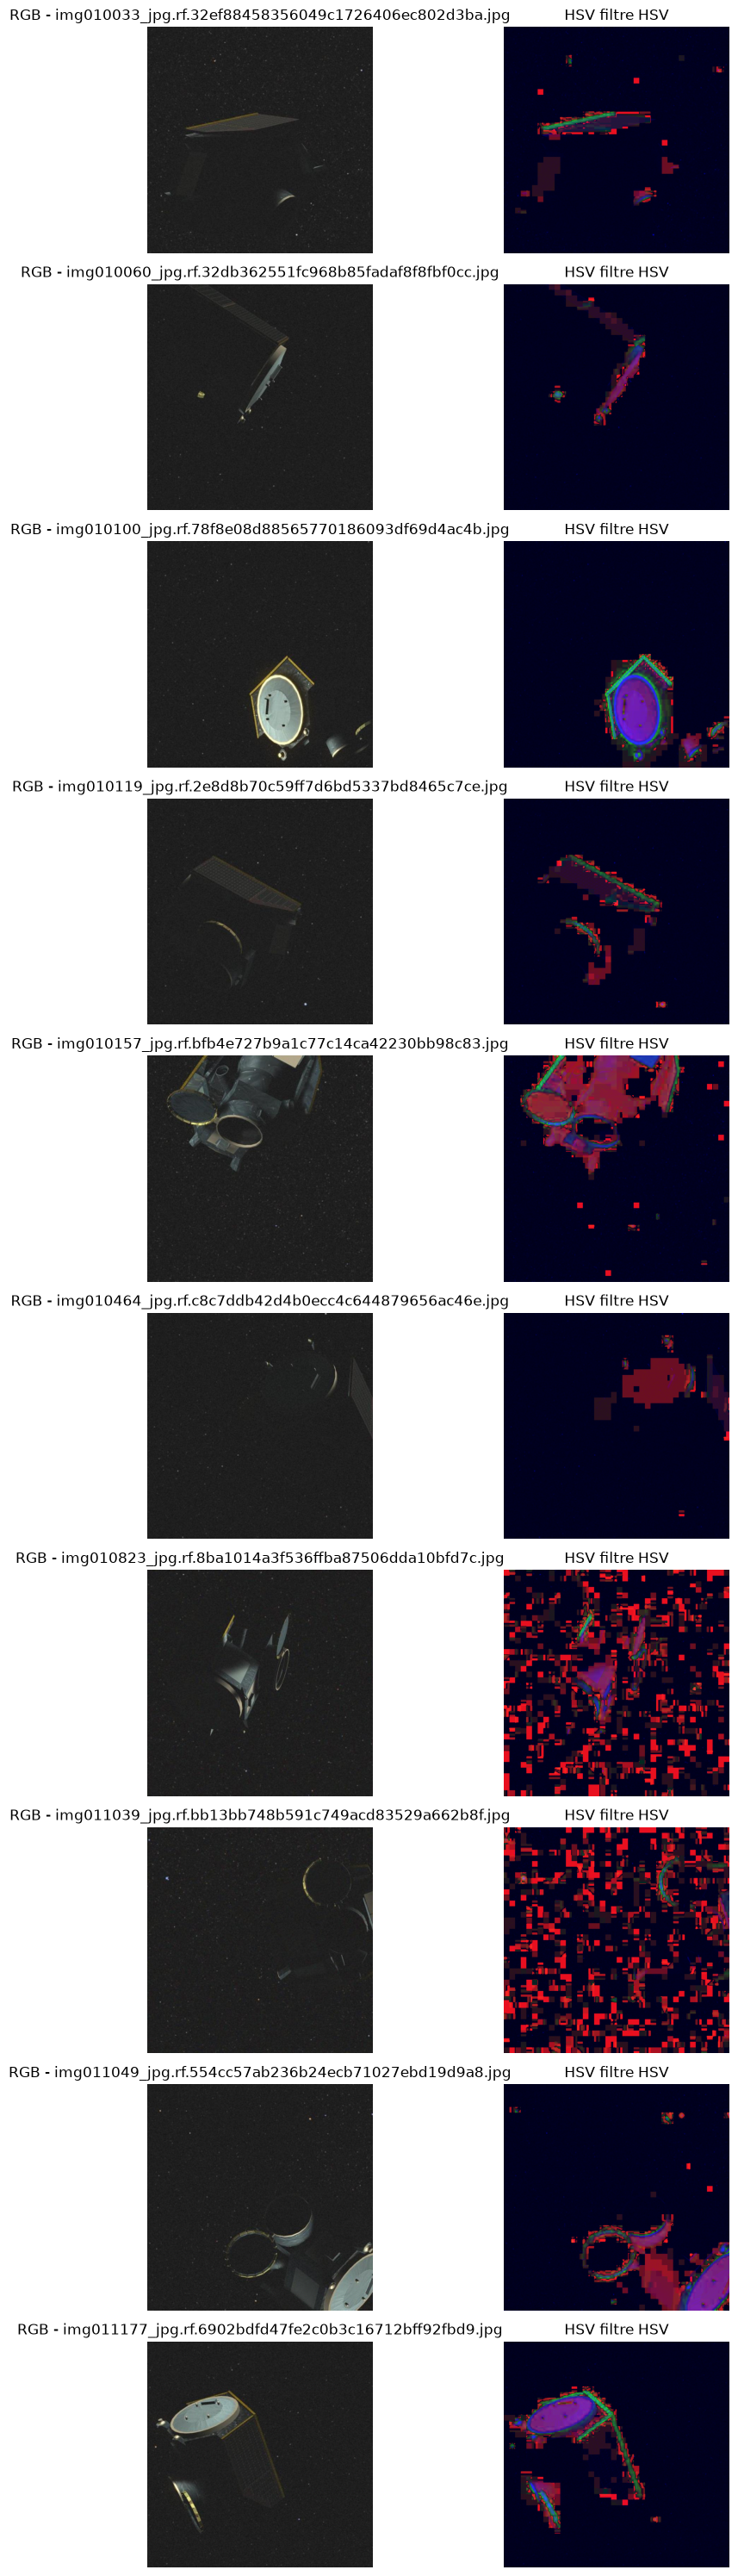

20 images filtrees avec le reglage HSV.


In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import rgb_to_hsv
from PIL import Image

images_dir = Path("data/test/images")
image_paths = sorted(
    path for path in images_dir.iterdir()
    if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
)[:20]

# Bornes reglables des trois composantes HSV : H (teinte), S (saturation), V (luminosite).
# Pour les modifier, conserver des valeurs comprises entre 0.0 et 1.0.
hue_range = (0.0, 1.0)
saturation_range = (0.0, 1.0)
value_range = (0.05, 1.0)

# Reinitialise les resultats pour ne pas reutiliser ceux d'une execution precedente.
hsv_images = []

# Traite chaque image individuellement.
for image_path in image_paths:
    # Charge l'image en RGB et normalise ses pixels entre 0 et 1.
    arr = np.asarray(Image.open(image_path).convert("RGB"), dtype=np.float32) / 255.0

    # Convertit l'image RGB dans l'espace HSV.
    hsv = rgb_to_hsv(arr)

    # Construit un masque qui conserve les surfaces sombres du satellite et ses reflets.
    mask = (
        (hsv[:, :, 0] >= hue_range[0]) & (hsv[:, :, 0] <= hue_range[1])
        & (hsv[:, :, 1] >= saturation_range[0]) & (hsv[:, :, 1] <= saturation_range[1])
        & (hsv[:, :, 2] >= value_range[0]) & (hsv[:, :, 2] <= value_range[1])
    )

    # Met a zero les pixels du fond qui ne respectent pas les plages HSV.
    hsv_filtered = hsv.copy()
    hsv_filtered[~mask] = 0.0
    hsv_images.append(hsv_filtered)

# Affiche les images par pages de 10.
images_per_page = 10
for page_start in range(0, len(image_paths), images_per_page):
    page_paths = image_paths[page_start:page_start + images_per_page]
    page_hsv = hsv_images[page_start:page_start + images_per_page]
    figure, axes = plt.subplots(len(page_paths), 2, figsize=(10, 3 * len(page_paths)))
    axes = np.atleast_2d(axes)

    # Affiche chaque paire RGB/HSV avec le nom du fichier.
    for row, (image_path, hsv) in enumerate(zip(page_paths, page_hsv)):
        arr = np.asarray(Image.open(image_path).convert("RGB"), dtype=np.float32) / 255.0
        axes[row, 0].imshow(arr)
        axes[row, 0].set_title(f"RGB - {image_path.name}")
        axes[row, 1].imshow(hsv)
        axes[row, 1].set_title("HSV filtre HSV")
        axes[row, 0].axis("off")
        axes[row, 1].axis("off")

    # Ajuste la mise en page, affiche la page et libere la figure.
    figure.tight_layout()
    plt.show()
    plt.close(figure)

print(f"{len(hsv_images)} images filtrees avec le reglage HSV.")

## 5. Construction du modèle multi-tâches

Construction d'un réseau convolutif. Ce modèle possède deux sorties :

- `class_output` prédit la classe de l'objet ;
- `bbox_output` prédit les quatre coordonnées de sa boîte englobante.

In [7]:
from tensorflow import keras
from tensorflow.keras import layers

# Entrée : image RGB redimensionnée en 224 x 224 pixels.
inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image_input")

x = layers.Conv2D(32, 3, activation="relu", padding="same")(inputs)
x = layers.MaxPooling2D()(x)
x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
x = layers.MaxPooling2D()(x)
x = layers.Conv2D(128, 3, activation="relu", padding="same")(x)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)

# Sortie classification : une probabilité par classe.
class_output = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="class_output",
)(x)

# Sortie localisation : quatre coordonnées normalisées entre 0 et 1.
bbox_output = layers.Dense(
    4,
    activation="sigmoid",
    name="bbox_output",
)(x)

model = keras.Model(
    inputs=inputs,
    outputs={
        "class_output": class_output,
        "bbox_output": bbox_output,
    },
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss={
        "class_output": keras.losses.SparseCategoricalCrossentropy(),
        "bbox_output": keras.losses.Huber(),
    },
    metrics={
        "class_output": ["accuracy"],
        "bbox_output": ["mae"],
    },
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │        896 │ image_input[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 112, 112,  │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 112, 112,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 56, 56,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 56, 56,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ conv2d_2[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     16,512 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bbox_output (Dense) │ (None, 4)         │        516 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_output        │ (None, 11)        │      1,419 │ dense[0][0]       │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 111,695 (436.31 KB)

 Trainable params: 111,695 (436.31 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Suivi de l'expérience avec Weights & Biases

`wandb` enregistre les paramètres, les pertes et les métriques de chaque entraînement. Il permet de comparer plusieurs expériences dans un tableau de bord.

In [8]:
import wandb
from wandb.integration.keras import WandbMetricsLogger

## 7. Entraînement du modèle

À chaque epoch, TensorFlow lit les images, calcule les deux prédictions, mesure les deux erreurs puis met à jour les poids du réseau. W&B reçoit les métriques grâce au callback `WandbMetricsLogger`.

In [ ]:
import wandb
from wandb.integration.keras import WandbMetricsLogger

EPOCHS = 10

wandb.login()

if wandb.run is not None:
    wandb.finish()

wandb.init(
    project="detecteur-objets-spatiaux",
    name="cnn-classification-localisation",
    config={
        "img_size": IMG_SIZE,
        "batch_size": BATCH_SIZE,
        "num_classes": NUM_CLASSES,
        "learning_rate": 0.001,
        "epochs": EPOCHS,
    },
)

wandb_metrics = WandbMetricsLogger(log_freq="epoch")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[
        wandb_metrics,
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True,
        ),
    ],
)

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/leo/.netrc.
wandb: Currently logged in as: leo-zory (leo-zory-cpe-lyon-formation-continue) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Epoch 1/10


/home/leo/Documents/AI & DEEP Learning/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


132/132 ━━━━━━━━━━━━━━━━━━━━ 76s 569ms/step - bbox_output_loss: 0.0240 - bbox_output_mae: 0.1793 - class_output_accuracy: 0.1302 - class_output_loss: 2.3386 - loss: 2.3625 - val_bbox_output_loss: 0.0167 - val_bbox_output_mae: 0.1509 - val_class_output_accuracy: 0.1004 - val_class_output_loss: 2.4702 - val_loss: 2.4527
Epoch 2/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 77s 582ms/step - bbox_output_loss: 0.0208 - bbox_output_mae: 0.1666 - class_output_accuracy: 0.1216 - class_output_loss: 2.3624 - loss: 2.3826 - val_bbox_output_loss: 0.0181 - val_bbox_output_mae: 0.1551 - val_class_output_accuracy: 0.1004 - val_class_output_loss: 2.5326 - val_loss: 2.4961
Epoch 3/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 73s 553ms/step - bbox_output_loss: 0.0214 - bbox_output_mae: 0.1676 - class_output_accuracy: 0.1392 - class_output_loss: 2.3265 - loss: 2.3476 - val_bbox_output_loss: 0.0167 - val_bbox_output_mae: 0.1507 - val_class_output_accuracy: 0.1004 - val_class_output_loss: 2.4586 - val_loss: 2.4381
Epoch 4/10
132/132

W0000 00:00:1791977737.329814   12603 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1791972859344841889 in buffer 'PrefetchDataset/_15' sat unconsumed for 4877.98 seconds!


132/132 ━━━━━━━━━━━━━━━━━━━━ 4975s 38s/step - bbox_output_loss: 0.0152 - bbox_output_mae: 0.1427 - class_output_accuracy: 0.4024 - class_output_loss: 1.3746 - loss: 1.3892 - val_bbox_output_loss: 0.0158 - val_bbox_output_mae: 0.1452 - val_class_output_accuracy: 0.3515 - val_class_output_loss: 1.3693 - val_loss: 1.3736
Epoch 9/10
 61/132 ━━━━━━━━━━━━━━━━━━━━ 38s 542ms/step - bbox_output_loss: 0.0145 - bbox_output_mae: 0.1388 - class_output_accuracy: 0.4334 - class_output_loss: 1.3132 - loss: 1.3277

## 8. Visualisation des courbes d'apprentissage

Les courbes permettent de comparer les performances sur les données d'entraînement et de validation.

In [ ]:
metrics = history.history

figure, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(history.epoch, metrics["loss"], label="train")
axes[0].plot(history.epoch, metrics["val_loss"], label="validation")
axes[0].set_title("Loss totale")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.epoch, metrics["class_output_accuracy"], label="train")
axes[1].plot(history.epoch, metrics["val_class_output_accuracy"], label="validation")
axes[1].set_title("Accuracy de classification")
axes[1].set_xlabel("Epoch")
axes[1].legend()

axes[2].plot(history.epoch, metrics["bbox_output_mae"], label="train")
axes[2].plot(history.epoch, metrics["val_bbox_output_mae"], label="validation")
axes[2].set_title("Erreur moyenne de localisation")
axes[2].set_xlabel("Epoch")
axes[2].legend()

plt.tight_layout()
plt.show()

## 9. Évaluation finale sur le jeu de test

Le jeu de test n'est pas utilisé pour modifier le modèle. Il sert uniquement à mesurer ses performances sur des images qu'il n'a pas vues pendant l'entraînement.

In [ ]:
test_results = model.evaluate(test_ds, return_dict=True)

print("Résultats sur le jeu de test :")
for metric_name, metric_value in test_results.items():
    print(f"{metric_name}: {metric_value:.4f}")

if wandb.run is not None:
    wandb.log({f"test/{name}": value for name, value in test_results.items()})
    wandb.finish()